In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path


In [2]:
# Load the dataset
df=pd.read_csv("European_Bank.csv")

In [3]:
df.head()

,Year,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,2025,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2025,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,2025,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,2025,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,2025,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [4]:
# Inspect dataset structure
print("Dataset shape:",df.shape)
print("\nColumn names:")
print(df.columns.tolist())
print("\n Dataset information:")
df.info()

Dataset shape: (10000, 14)

Column names:
['Year', 'CustomerId', 'Surname', 'CreditScore', 'Geography', 'Gender', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary', 'Exited']

 Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Year             10000 non-null  int64  
 1   CustomerId       10000 non-null  int64  
 2   Surname          10000 non-null  str    
 3   CreditScore      10000 non-null  int64  
 4   Geography        10000 non-null  str    
 5   Gender           10000 non-null  str    
 6   Age              10000 non-null  int64  
 7   Tenure           10000 non-null  int64  
 8   Balance          10000 non-null  float64
 9   NumOfProducts    10000 non-null  int64  
 10  HasCrCard        10000 non-null  int64  
 11  IsActiveMember   10000 non-null  int64  
 12  EstimatedSal

In [5]:
missing_count=df.isnull().sum()
missing_count

Year               0
CustomerId         0
Surname            0
CreditScore        0
Geography          0
Gender             0
Age                0
Tenure             0
Balance            0
NumOfProducts      0
HasCrCard          0
IsActiveMember     0
EstimatedSalary    0
Exited             0
dtype: int64

In [6]:
# Check duplicate records
duplicate_rows=df.duplicated().sum()
duplicate_rows

np.int64(0)

In [7]:
df["CustomerId"].duplicated().sum()

np.int64(0)

In [8]:
# Validate categories and binary variables
print("Geography values:")
print(df["Geography"].value_counts(dropna=False))
print("\nGender Values:")
print(df["Gender"].value_counts(dropna=False))

Geography values:
Geography
France     5014
Germany    2509
Spain      2477
Name: count, dtype: int64

Gender Values:
Gender
Male      5457
Female    4543
Name: count, dtype: int64


In [9]:
# Check numeric range
numeric_columns=["Year","CreditScore","Age","Tenure","Balance","NumOfProducts","EstimatedSalary"]
print(df[numeric_columns].describe().T)

                   count           mean           std      min       25%  \
Year             10000.0    2025.000000      0.000000  2025.00   2025.00   
CreditScore      10000.0     650.528800     96.653299   350.00    584.00   
Age              10000.0      38.921800     10.487806    18.00     32.00   
Tenure           10000.0       5.012800      2.892174     0.00      3.00   
Balance          10000.0   76485.889288  62397.405202     0.00      0.00   
NumOfProducts    10000.0       1.530200      0.581654     1.00      1.00   
EstimatedSalary  10000.0  100090.239881  57510.492818    11.58  51002.11   

                        50%          75%        max  
Year               2025.000    2025.0000    2025.00  
CreditScore         652.000     718.0000     850.00  
Age                  37.000      44.0000      92.00  
Tenure                5.000       7.0000      10.00  
Balance           97198.540  127644.2400  250898.09  
NumOfProducts         1.000       2.0000       4.00  
EstimatedSala

In [10]:
# Create a data-quality report
binary_columns=["HasCrCard","IsActiveMember","Exited"]
quality_report=pd.DataFrame({
    "Check":[
        "Total records",
        "Total columns",
        "Missing cells",
        "Duplicate rows",
        "Duplicate customer IDs",
        "Invalid binary values",
        "Unexpected geography values",
        "Unexpected gender values"
    ],
    "Result":[
        len(df),
        df.shape[1],
        int(df.isnull().sum().sum()),
        int(df.duplicated().sum()),
        int(df["CustomerId"].duplicated().sum()),
        int(sum((-df[col].isin([0,1])).sum()
            for col in binary_columns)),
        int((~df["Geography"].isin(["France","Spain","Germany"])).sum()),
        int((~df["Gender"].isin(["Male","Female"])).sum())
    ]

})
print(quality_report.to_string(index=False))


                      Check  Result
              Total records   10000
              Total columns      14
              Missing cells       0
             Duplicate rows       0
     Duplicate customer IDs       0
      Invalid binary values       0
Unexpected geography values       0
   Unexpected gender values       0


  Customer_Status  Customers  Percentage
0        Retained       7963       79.63
1         Churned       2037       20.37


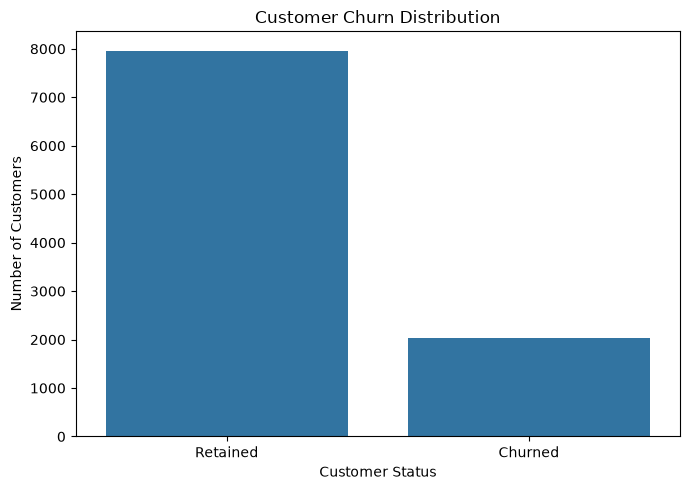

In [11]:
# Churn Distribution
churn_counts=(
df["Exited"].value_counts().sort_index())
churn_summary=pd.DataFrame({
    "Customer_Status":["Retained","Churned"],
    "Customers":[churn_counts.get(0,0),churn_counts.get(1,0)]
})
churn_summary["Percentage"]=(
    churn_summary["Customers"]/len(df)*100
).round(2)
print(churn_summary)
plt.figure(figsize=(7,5))
sns.barplot(
    data=churn_summary,
    x="Customer_Status",
    y="Customers")
plt.title("Customer Churn Distribution")
plt.xlabel("Customer Status")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()

   IsActiveMember  Customers  Churned_Customers  Churn_Rate Engagement_Status
0               0       4849               1302       26.85          Inactive
1               1       5151                735       14.27            Active


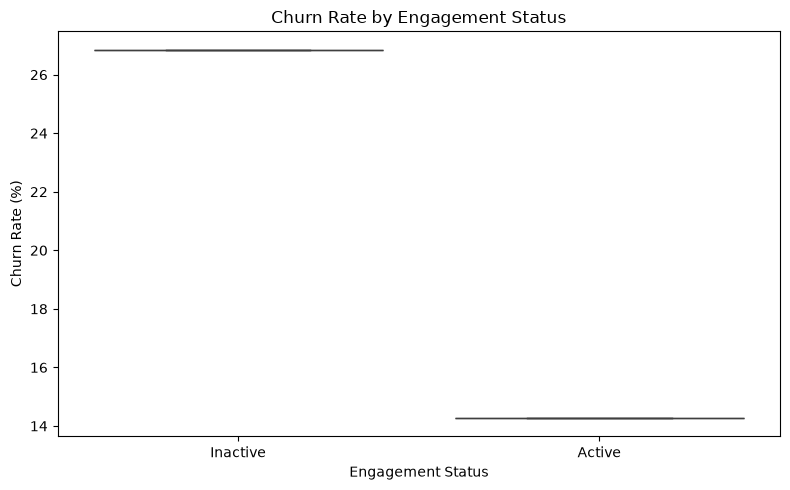

In [12]:
# Engagement Analysis
engagement_summary=(
    df.groupby("IsActiveMember")
    .agg(
        Customers=("CustomerId","count"),
        Churned_Customers=("Exited","sum"),
        Churn_Rate=("Exited","mean")
    )
    .reset_index()
)
engagement_summary["Churn_Rate"]*=100
engagement_summary["Engagement_Status"]=(
   engagement_summary["IsActiveMember"]
   .map({0:"Inactive",1:"Active"}) 
)
print(engagement_summary.round(2))
plt.figure(figsize=(8,5))
sns.boxplot(
    data=engagement_summary,
    x="Engagement_Status",
    y="Churn_Rate"
)
plt.title("Churn Rate by Engagement Status")
plt.xlabel("Engagement Status")
plt.ylabel("Churn Rate (%)")
plt.tight_layout()
plt.show()

   NumOfProducts  Customers  Churn_Customers  Churn_Rate
0              1       5084             1409       27.71
1              2       4590              348        7.58
2              3        266              220       82.71
3              4         60               60      100.00


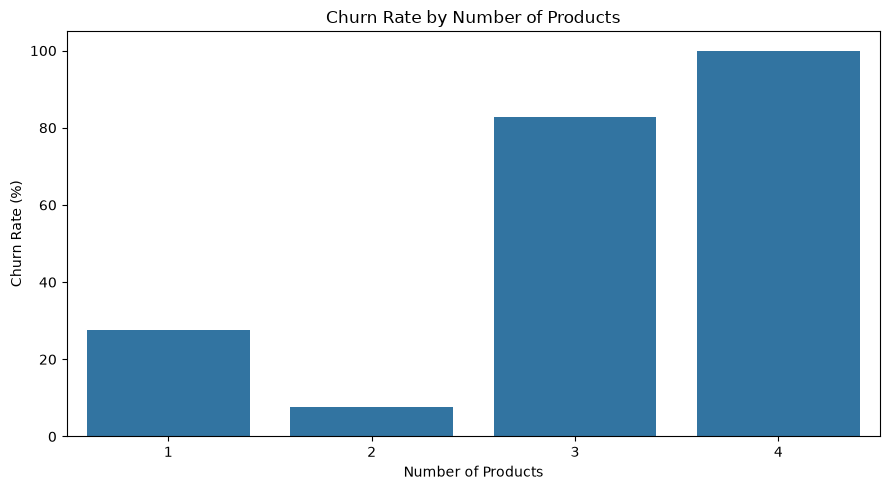

In [13]:
# Product utilization analysis
product_summary=(
    df.groupby("NumOfProducts")
    .agg(
        Customers=("CustomerId","count"),
        Churn_Customers=("Exited","sum"),
        Churn_Rate=("Exited","mean")
    ).reset_index()
)
product_summary["Churn_Rate"]*=100
print(product_summary.round(2))
plt.figure(figsize=(9,5))
sns.barplot(
    data=product_summary,
    x="NumOfProducts",
    y="Churn_Rate"
)
plt.title("Churn Rate by Number of Products")
plt.xlabel("Number of Products")
plt.ylabel("Churn Rate (%)")
plt.tight_layout()
plt.show()

  Geography  Customers  Churned_Customers  Churned_Rate
0    France       5014                810         16.15
1   Germany       2509                814         32.44
2     Spain       2477                413         16.67

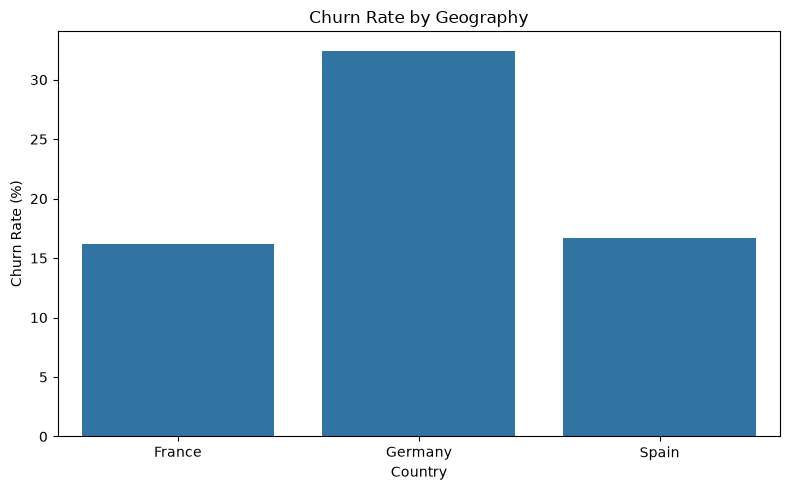

In [14]:
# Geography Analysis
geography_summary=(
    df.groupby("Geography")
    .agg(
        Customers=("CustomerId","count"),
        Churned_Customers=("Exited","sum"),
        Churned_Rate=("Exited","mean")
    ).reset_index()
)
geography_summary["Churned_Rate"]*=100
print(geography_summary.round(2))
plt.figure(figsize=(8,5))
sns.barplot(
            data=geography_summary,
            x="Geography",
            y="Churned_Rate"
            )
plt.title("Churn Rate by Geography")
plt.xlabel("Country")
plt.ylabel("Churn Rate (%)")
plt.tight_layout()
plt.show()

  AgeGroup  Customers  Churned_Customers  Churn_Rate
0    18-25        611                 46        7.53
1    26-35       3542                301        8.50
2    36-45       3736                733       19.62
3    46-55       1311                663       50.57
4    56-65        536                259       48.32
5      66+        264                 35       13.26


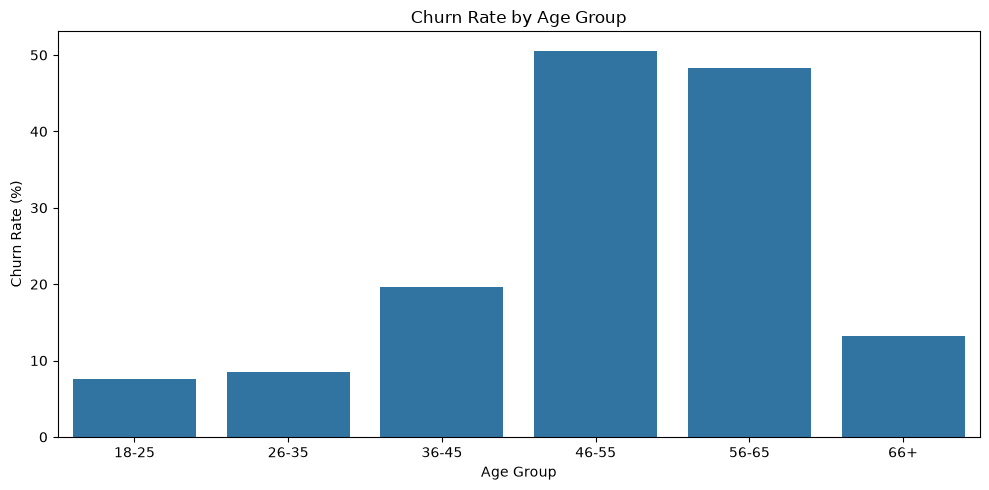

In [15]:

# Age group analysis

df["AgeGroup"] = pd.cut(
    df["Age"],
    bins=[17, 25, 35, 45, 55, 65, 120],
    labels=[
        "18-25", "26-35", "36-45",
        "46-55", "56-65", "66+"
    ]
)

age_summary = (
    df.groupby("AgeGroup", observed=False)
    .agg(
        Customers=("CustomerId", "count"),
        Churned_Customers=("Exited", "sum"),
        Churn_Rate=("Exited", "mean")
    )
    .reset_index()
)

age_summary["Churn_Rate"] *= 100

print(age_summary.round(2))

plt.figure(figsize=(10, 5))
sns.barplot(
    data=age_summary,
    x="AgeGroup",
    y="Churn_Rate"
)
plt.title("Churn Rate by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Churn Rate (%)")
plt.tight_layout()
plt.show()


  BalanceGroup  Customers  Churned_Customers  Churn_Rate
0         Zero       3617                500       13.82
1        0-50k         75                 26       34.67
2      50-100k       1509                300       19.88
3     100-150k       3830                987       25.77
4     150-200k        935                205       21.93
5        200k+         34                 19       55.88


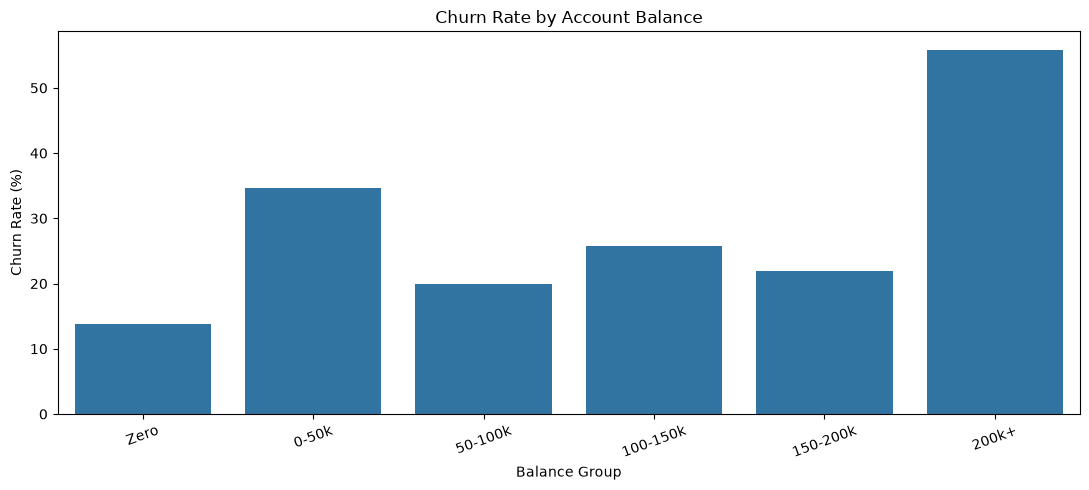

In [16]:

# Balance group analysis

df["BalanceGroup"] = pd.cut(
    df["Balance"],
    bins=[-1, 0, 50000, 100000, 150000, 200000, float("inf")],
    labels=[
        "Zero", "0-50k", "50-100k",
        "100-150k", "150-200k", "200k+"
    ]
)

balance_summary = (
    df.groupby("BalanceGroup", observed=False)
    .agg(
        Customers=("CustomerId", "count"),
        Churned_Customers=("Exited", "sum"),
        Churn_Rate=("Exited", "mean")
    )
    .reset_index()
)

balance_summary["Churn_Rate"] *= 100

print(balance_summary.round(2))

plt.figure(figsize=(11, 5))
sns.barplot(
    data=balance_summary,
    x="BalanceGroup",
    y="Churn_Rate"
)
plt.title("Churn Rate by Account Balance")
plt.xlabel("Balance Group")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()


   IsActiveMember  NumOfProducts  Customers  Churned_Customers  Churn_Rate
0               0              1       2521                924       36.65
1               0              2       2144                212        9.89
2               0              3        153                135       88.24
3               0              4         31                 31      100.00
4               1              1       2563                485       18.92
5               1              2       2446                136        5.56
6               1              3        113                 85       75.22
7               1              4         29                 29      100.00


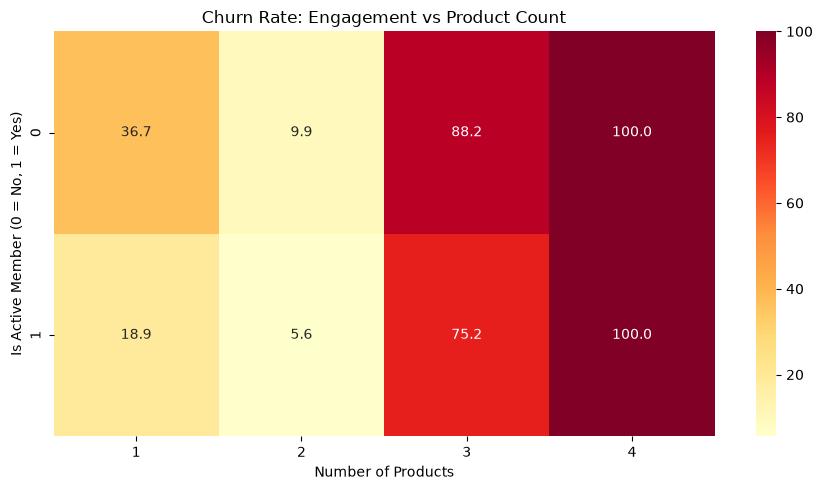

In [17]:

# Engagement and product count cross-analysis

engagement_product = (
    df.groupby(
        ["IsActiveMember", "NumOfProducts"]
    )
    .agg(
        Customers=("CustomerId", "count"),
        Churned_Customers=("Exited", "sum"),
        Churn_Rate=("Exited", "mean")
    )
    .reset_index()
)

engagement_product["Churn_Rate"] *= 100

print(engagement_product.round(2))

heatmap_data = df.pivot_table(
    index="IsActiveMember",
    columns="NumOfProducts",
    values="Exited",
    aggfunc="mean"
) * 100

plt.figure(figsize=(9, 5))
sns.heatmap(
    heatmap_data,
    annot=True,
    fmt=".1f",
    cmap="YlOrRd"
)
plt.title("Churn Rate: Engagement vs Product Count")
plt.xlabel("Number of Products")
plt.ylabel("Is Active Member (0 = No, 1 = Yes)")
plt.tight_layout()
plt.show()


In [18]:

# Additional churn analysis

for col in ["HasCrCard", "Tenure"]:
    summary = (
        df.groupby(col)
        .agg(
            Customers=("CustomerId", "count"),
            Churned=("Exited", "sum"),
            Churn_Rate=("Exited", "mean")
        )
    )

    summary["Churn_Rate"] *= 100

    print(f"\nChurn analysis by {col}:")
    print(summary.round(2))

# Compare numeric characteristics by churn status
numeric_cols = [
    "CreditScore",
    "Age",
    "Tenure",
    "Balance",
    "NumOfProducts",
    "EstimatedSalary"
]

print("\nNumeric characteristics by churn status:")
print(df.groupby("Exited")[numeric_cols].mean().round(2))



Churn analysis by HasCrCard:
           Customers  Churned  Churn_Rate
HasCrCard                                
0               2945      613       20.81
1               7055     1424       20.18

Churn analysis by Tenure:
        Customers  Churned  Churn_Rate
Tenure                                
0             413       95       23.00
1            1035      232       22.42
2            1048      201       19.18
3            1009      213       21.11
4             989      203       20.53
5            1012      209       20.65
6             967      196       20.27
7            1028      177       17.22
8            1025      197       19.22
9             984      213       21.65
10            490      101       20.61

Numeric characteristics by churn status:
        CreditScore    Age  Tenure   Balance  NumOfProducts  EstimatedSalary
Exited                                                                      
0            651.85  37.41    5.03  72745.30           1.54         9973

Exited             1.000
Age                0.285
Balance            0.119
EstimatedSalary    0.012
HasCrCard         -0.007
Tenure            -0.014
CreditScore       -0.027
NumOfProducts     -0.048
IsActiveMember    -0.156
Name: Exited, dtype: float64


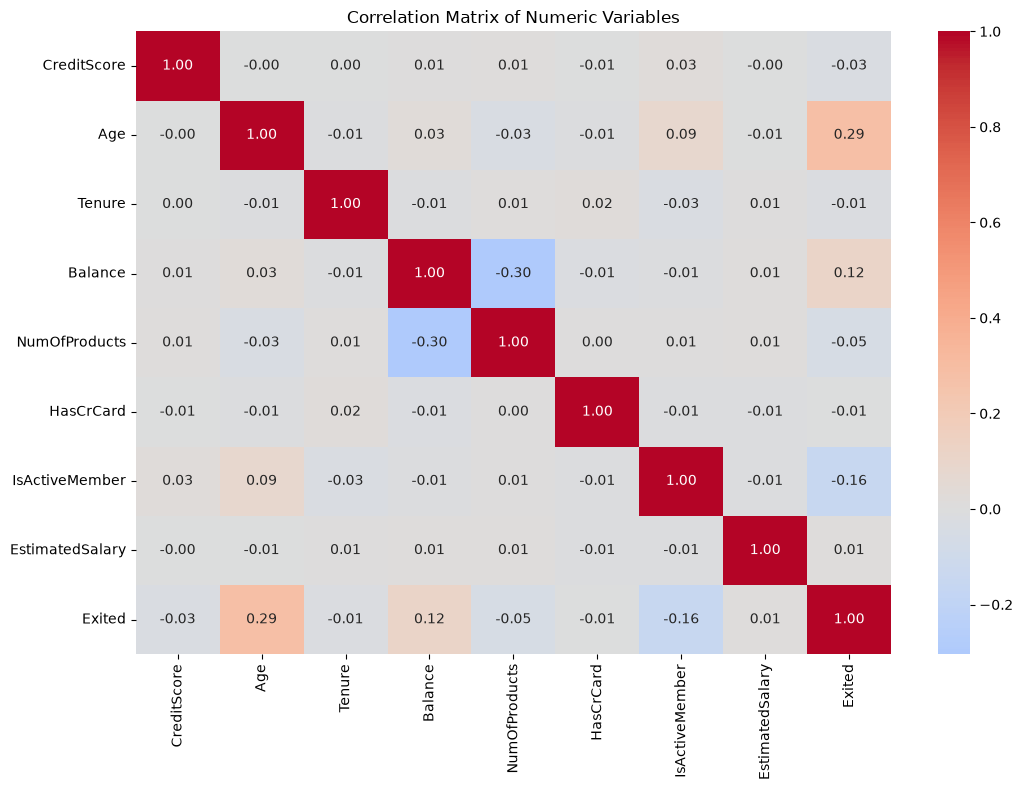

In [19]:

# Correlation analysis

correlation_cols = [
    "CreditScore",
    "Age",
    "Tenure",
    "Balance",
    "NumOfProducts",
    "HasCrCard",
    "IsActiveMember",
    "EstimatedSalary",
    "Exited"
]

corr_matrix = df[correlation_cols].corr()

print(
    corr_matrix["Exited"]
    .sort_values(ascending=False)
    .round(3)
)

plt.figure(figsize=(11, 8))
sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)
plt.title("Correlation Matrix of Numeric Variables")
plt.tight_layout()
plt.show()


In [20]:

# High-balance disengaged customer screening

at_risk_customers = df[
    (df["IsActiveMember"] == 0) &
    (df["Balance"] >= 100000) &
    (df["Exited"] == 0)
].copy()

customer_columns = [
    "CustomerId",
    "Geography",
    "Age",
    "Tenure",
    "Balance",
    "NumOfProducts",
    "IsActiveMember",
    "Exited"
]

at_risk_customers = (
    at_risk_customers[customer_columns]
    .sort_values("Balance", ascending=False)
)

print("Potentially at-risk retained customers:",
      len(at_risk_customers))

print("\nTotal balance of this segment:",
      round(at_risk_customers["Balance"].sum(), 2))

at_risk_customers.head(10)


Potentially at-risk retained customers: 1584

Total balance of this segment: 210626535.62


,CustomerId,Geography,Age,Tenure,Balance,NumOfProducts,IsActiveMember,Exited
3588,15571958,Spain,40,3,221532.80,1,0,0
1067,15599131,Germany,26,4,214346.96,2,0,0
3920,15620268,Germany,43,3,212696.32,1,0,0
2709,15780212,France,37,4,212692.97,1,0,0
8982,15627971,France,32,8,206663.75,1,0,0
4436,15664498,France,26,7,205962.00,1,0,0
7887,15745433,Germany,30,2,205770.78,2,0,0
5254,15746664,Spain,20,8,204223.03,1,0,0
8063,15663888,Germany,34,6,204017.40,2,0,0
7632,15620570,France,43,4,202443.47,1,0,0


In [22]:



HIGH_BALANCE_THRESHOLD = 100_000
MAX_PRODUCTS = 4

# Basic validation before calculating KPIs
required_columns = [
    "CustomerId", "NumOfProducts", "HasCrCard",
    "IsActiveMember", "Exited", "Balance"
]

missing_columns = set(required_columns) - set(df.columns)

if missing_columns:
    raise ValueError(f"Missing required columns: {missing_columns}")

if df["CustomerId"].duplicated().any():
    raise ValueError("Customer IDs are not unique.")

if df["Exited"].isna().any() or not df["Exited"].isin([0, 1]).all():
    raise ValueError("Exited must contain only 0 and 1.")

if not df["IsActiveMember"].isin([0, 1]).all():
    raise ValueError("IsActiveMember must contain only 0 and 1.")

if not df["HasCrCard"].isin([0, 1]).all():
    raise ValueError("HasCrCard must contain only 0 and 1.")

if not df["NumOfProducts"].between(1, MAX_PRODUCTS).all():
    raise ValueError("Unexpected product count found.")

print("Dataset validated for KPI calculations.")
print("Total customers:", len(df))
print("High-balance threshold:", HIGH_BALANCE_THRESHOLD)


Dataset validated for KPI calculations.
Total customers: 10000
High-balance threshold: 100000


In [23]:

# KPI 1: Engagement Retention Ratio

engagement_kpi = (
    df.groupby("IsActiveMember")
    .agg(
        Customers=("CustomerId", "count"),
        Churned=("Exited", "sum"),
        Churn_Rate=("Exited", "mean")
    )
)

engagement_kpi["Retention_Rate"] = (
    1 - engagement_kpi["Churn_Rate"]
)

active_retention = engagement_kpi.loc[1, "Retention_Rate"]
inactive_retention = engagement_kpi.loc[0, "Retention_Rate"]

engagement_retention_ratio = (
    active_retention / inactive_retention
    if inactive_retention != 0 else np.nan
)

print(engagement_kpi.round(4))
print(
    "\nEngagement Retention Ratio:",
    round(engagement_retention_ratio, 4)
)
print(
    "Active retention rate:",
    f"{active_retention:.2%}"
)
print(
    "Inactive retention rate:",
    f"{inactive_retention:.2%}"
)


                Customers  Churned  Churn_Rate  Retention_Rate
IsActiveMember                                                
0                    4849     1302      0.2685          0.7315
1                    5151      735      0.1427          0.8573

Engagement Retention Ratio: 1.172
Active retention rate: 85.73%
Inactive retention rate: 73.15%


In [24]:

# KPI 2: Product Depth Index

total_products = df["NumOfProducts"].sum()
total_customers = df["CustomerId"].nunique()

product_depth_index = total_products / total_customers

print("Total products held:", total_products)
print("Unique customers:", total_customers)
print("Product Depth Index:", round(product_depth_index, 4))

# Retention and churn by product count
product_kpi = (
    df.groupby("NumOfProducts")
    .agg(
        Customers=("CustomerId", "count"),
        Total_Products=("NumOfProducts", "sum"),
        Churned=("Exited", "sum"),
        Churn_Rate=("Exited", "mean")
    )
    .reset_index()
)

product_kpi["Retention_Rate"] = 1 - product_kpi["Churn_Rate"]
product_kpi["Churn_Rate"] *= 100
product_kpi["Retention_Rate"] *= 100

print("\nProduct-level KPI table:")
print(product_kpi.round(2))


Total products held: 15302
Unique customers: 10000
Product Depth Index: 1.5302

Product-level KPI table:
   NumOfProducts  Customers  Total_Products  Churned  Churn_Rate  \
0              1       5084            5084     1409       27.71   
1              2       4590            9180      348        7.58   
2              3        266             798      220       82.71   
3              4         60             240       60      100.00   

   Retention_Rate  
0           72.29  
1           92.42  
2           17.29  
3            0.00  


In [25]:

# KPI 3: High-Balance Disengagement Rate

high_balance_df = df[
    df["Balance"] >= HIGH_BALANCE_THRESHOLD
].copy()

high_balance_total = len(high_balance_df)

high_balance_inactive = (
    high_balance_df["IsActiveMember"] == 0
).sum()

high_balance_disengagement_rate = (
    high_balance_inactive / high_balance_total * 100
    if high_balance_total > 0 else np.nan
)

high_balance_churn_rate = (
    high_balance_df["Exited"].mean() * 100
    if high_balance_total > 0 else np.nan
)

print("High-balance customers:", high_balance_total)
print("Inactive high-balance customers:", high_balance_inactive)
print(
    "High-Balance Disengagement Rate:",
    f"{high_balance_disengagement_rate:.2f}%"
)
print(
    "Churn rate among high-balance customers:",
    f"{high_balance_churn_rate:.2f}%"
)

# Identify retained customers for potential re-engagement
high_value_disengaged = high_balance_df[
    (high_balance_df["IsActiveMember"] == 0) &
    (high_balance_df["Exited"] == 0)
].copy()

print(
    "\nRetained, inactive, high-balance customers:",
    len(high_value_disengaged)
)


High-balance customers: 4799
Inactive high-balance customers: 2356
High-Balance Disengagement Rate: 49.09%
Churn rate among high-balance customers: 25.23%

Retained, inactive, high-balance customers: 1584


In [26]:

# KPI 4: Credit Card Stickiness Score

card_kpi = (
    df.groupby("HasCrCard")
    .agg(
        Customers=("CustomerId", "count"),
        Churned=("Exited", "sum"),
        Churn_Rate=("Exited", "mean")
    )
)

card_kpi["Retention_Rate"] = 1 - card_kpi["Churn_Rate"]

cardholder_retention = card_kpi.loc[1, "Retention_Rate"]
non_cardholder_retention = card_kpi.loc[0, "Retention_Rate"]

credit_card_stickiness_score = (
    cardholder_retention / non_cardholder_retention
    if non_cardholder_retention != 0 else np.nan
)

print(card_kpi.round(4))
print(
    "\nCredit Card Stickiness Score:",
    round(credit_card_stickiness_score, 4)
)
print(
    "Cardholder retention:",
    f"{cardholder_retention:.2%}"
)
print(
    "Non-cardholder retention:",
    f"{non_cardholder_retention:.2%}"
)


           Customers  Churned  Churn_Rate  Retention_Rate
HasCrCard                                                
0               2945      613      0.2081          0.7919
1               7055     1424      0.2018          0.7982

Credit Card Stickiness Score: 1.008
Cardholder retention: 79.82%
Non-cardholder retention: 79.19%


In [27]:

# KPI 5: Relationship Strength Index

relationship_df = df.copy()

relationship_df["Activity_Score"] = (
    relationship_df["IsActiveMember"] * 100
)

relationship_df["Product_Score"] = (
    relationship_df["NumOfProducts"] / MAX_PRODUCTS * 100
)

relationship_df["Relationship_Strength_Index"] = (
    relationship_df["Activity_Score"] +
    relationship_df["Product_Score"]
) / 2

print(
    relationship_df[
        [
            "CustomerId",
            "IsActiveMember",
            "NumOfProducts",
            "Activity_Score",
            "Product_Score",
            "Relationship_Strength_Index"
        ]
    ].head(10)
)

print(
    "\nAverage Relationship Strength Index:",
    round(
        relationship_df["Relationship_Strength_Index"].mean(),
        2
    )
)


   CustomerId  IsActiveMember  NumOfProducts  Activity_Score  Product_Score  \
0    15634602               1              1             100           25.0   
1    15647311               1              1             100           25.0   
2    15619304               0              3               0           75.0   
3    15701354               0              2               0           50.0   
4    15737888               1              1             100           25.0   
5    15574012               0              2               0           50.0   
6    15592531               1              2             100           50.0   
7    15656148               0              4               0          100.0   
8    15792365               1              2             100           50.0   
9    15592389               1              1             100           25.0   

   Relationship_Strength_Index  
0                         62.5  
1                         62.5  
2                         37.5 

In [28]:

# Step 8: Consolidate all five KPIs

kpi_summary = pd.DataFrame([
    {
        "KPI": "Engagement Retention Ratio",
        "Value": engagement_retention_ratio,
        "Unit": "Ratio",
        "Interpretation": "Active vs inactive retention"
    },
    {
        "KPI": "Product Depth Index",
        "Value": product_depth_index,
        "Unit": "Products per customer",
        "Interpretation": "Average products held"
    },
    {
        "KPI": "High-Balance Disengagement Rate",
        "Value": high_balance_disengagement_rate,
        "Unit": "%",
        "Interpretation": "Inactive share of high-balance customers"
    },
    {
        "KPI": "Credit Card Stickiness Score",
        "Value": credit_card_stickiness_score,
        "Unit": "Ratio",
        "Interpretation": "Cardholder vs non-cardholder retention"
    },
    {
        "KPI": "Relationship Strength Index",
        "Value": relationship_df[
            "Relationship_Strength_Index"
        ].mean(),
        "Unit": "Score out of 100",
        "Interpretation": "Average activity and product score"
    }
])

print(kpi_summary.round(4).to_string(index=False))


                            KPI   Value                  Unit                           Interpretation
     Engagement Retention Ratio  1.1720                 Ratio             Active vs inactive retention
            Product Depth Index  1.5302 Products per customer                    Average products held
High-Balance Disengagement Rate 49.0936                     % Inactive share of high-balance customers
   Credit Card Stickiness Score  1.0080                 Ratio   Cardholder vs non-cardholder retention
    Relationship Strength Index 44.8825      Score out of 100       Average activity and product score


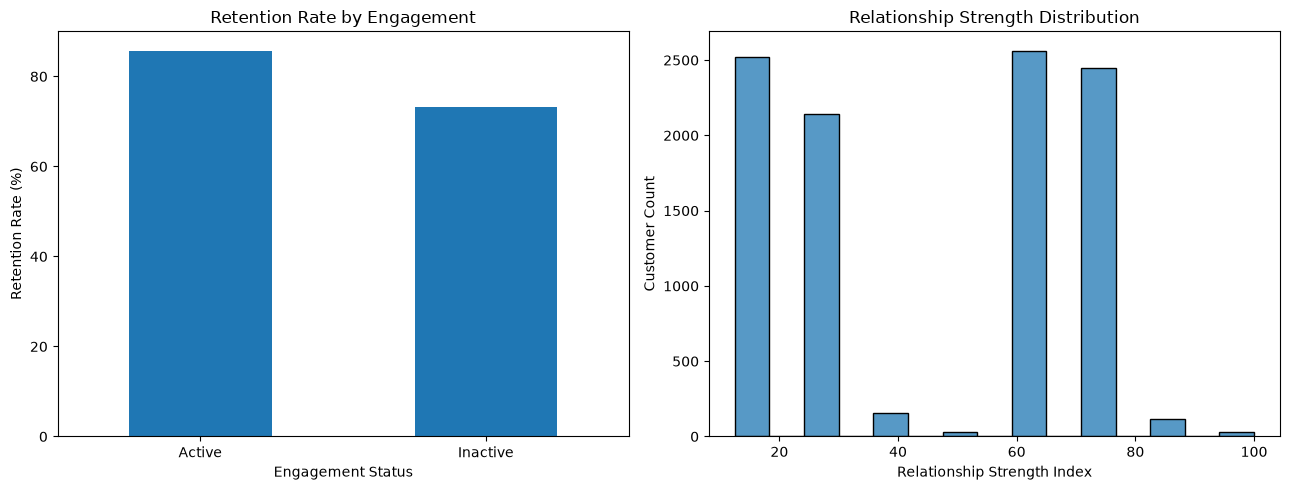

In [29]:

# Step 9: Plot the KPI results

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Retention comparison
retention_data = pd.Series({
    "Active": active_retention * 100,
    "Inactive": inactive_retention * 100
})

retention_data.plot(
    kind="bar",
    ax=axes[0]
)

axes[0].set_title("Retention Rate by Engagement")
axes[0].set_ylabel("Retention Rate (%)")
axes[0].set_xlabel("Engagement Status")
axes[0].tick_params(axis="x", rotation=0)

# Relationship strength distribution
sns.histplot(
    data=relationship_df,
    x="Relationship_Strength_Index",
    bins=15,
    ax=axes[1]
)

axes[1].set_title("Relationship Strength Distribution")
axes[1].set_xlabel("Relationship Strength Index")
axes[1].set_ylabel("Customer Count")

plt.tight_layout()
plt.show()


In [30]:

# Step 10: Export KPI outputs

output_dir = Path("outputs")
output_dir.mkdir(parents=True, exist_ok=True)

kpi_summary.to_csv(
    output_dir / "phase_3_kpi_summary.csv",
    index=False
)

product_kpi.to_csv(
    output_dir / "phase_3_product_kpi.csv",
    index=False
)

engagement_kpi.to_csv(
    output_dir / "phase_3_engagement_kpi.csv"
)

card_kpi.to_csv(
    output_dir / "phase_3_credit_card_kpi.csv"
)

relationship_df.to_csv(
    output_dir / "phase_3_relationship_strength.csv",
    index=False
)

high_value_disengaged.to_csv(
    output_dir / "phase_3_high_balance_disengaged.csv",
    index=False
)

print("Phase 3 KPI outputs saved successfully.")
print("Output directory:", output_dir.resolve())


Phase 3 KPI outputs saved successfully.
Output directory: D:\Data Analytics\ReClasses\Internship Projects\Unified Mentor\Project 2\outputs


In [31]:


from pathlib import Path



overall_churn_rate = df["Exited"].mean() * 100

# Define analysis segments
df["Engagement_Segment"] = np.where(
    df["IsActiveMember"] == 1,
    "Active",
    "Inactive"
)

df["Product_Segment"] = np.select(
    [
        df["NumOfProducts"] == 1,
        df["NumOfProducts"] == 2,
        df["NumOfProducts"] >= 3
    ],
    [
        "1 Product",
        "2 Products",
        "3+ Products"
    ],
    default="Other"
)

df["Balance_Segment"] = np.where(
    df["Balance"] >= 100000,
    "High Balance",
    "Lower Balance"
)

df["Customer_Priority_Segment"] = np.select(
    [
        (df["IsActiveMember"] == 0) &
        (df["Balance"] >= 100000),

        (df["IsActiveMember"] == 0) &
        (df["NumOfProducts"] == 1),

        (df["IsActiveMember"] == 1) &
        (df["NumOfProducts"] >= 3)
    ],
    [
        "Inactive + High Balance",
        "Inactive + 1 Product",
        "Active + 3 or More Products"
    ],
    default="Other Customers"
)

# Summarize the priority segments
segment_summary = (
    df.groupby("Customer_Priority_Segment")
    .agg(
        Customers=("CustomerId", "count"),
        Churned=("Exited", "sum"),
        Average_Balance=("Balance", "mean"),
        Average_Products=("NumOfProducts", "mean")
    )
    .reset_index()
)

segment_summary["Churn_Rate_Pct"] = (
    segment_summary["Churned"] /
    segment_summary["Customers"] * 100
)

segment_summary["Difference_vs_Overall_pp"] = (
    segment_summary["Churn_Rate_Pct"] -
    overall_churn_rate
)

print("Overall churn rate:", round(overall_churn_rate, 2), "%")
print(segment_summary.round(2).to_string(index=False))


Overall churn rate: 20.37 %
  Customer_Priority_Segment  Customers  Churned  Average_Balance  Average_Products  Churn_Rate_Pct  Difference_vs_Overall_pp
Active + 3 or More Products        142      114         74057.29              3.20           80.28                     59.91
       Inactive + 1 Product        944      367         41112.82              1.00           38.88                     18.51
    Inactive + High Balance       2356      772        132540.51              1.38           32.77                     12.40
            Other Customers       6558      784         61492.35              1.62           11.95                     -8.42


In [32]:

# High-value disengaged customer analysis

high_value_disengaged = df[
    (df["Balance"] >= 100000) &
    (df["IsActiveMember"] == 0) &
    (df["Exited"] == 0)
].copy()

priority_summary = pd.DataFrame({
    "Metric": [
        "Eligible retained customers",
        "Total balance of eligible customers",
        "Average balance per customer",
        "Average number of products"
    ],
    "Value": [
        len(high_value_disengaged),
        high_value_disengaged["Balance"].sum(),
        high_value_disengaged["Balance"].mean(),
        high_value_disengaged["NumOfProducts"].mean()
    ]
})

print(priority_summary.round(2).to_string(index=False))

customer_view = high_value_disengaged[
    [
        "CustomerId",
        "Geography",
        "Age",
        "Tenure",
        "Balance",
        "NumOfProducts",
        "HasCrCard",
        "IsActiveMember",
        "Exited"
    ]
].sort_values("Balance", ascending=False)

customer_view.head(10)


                             Metric        Value
        Eligible retained customers      1584.00
Total balance of eligible customers 210626535.62
       Average balance per customer    132971.30
         Average number of products         1.36


,CustomerId,Geography,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,Exited
3588,15571958,Spain,40,3,221532.80,1,1,0,0
1067,15599131,Germany,26,4,214346.96,2,1,0,0
3920,15620268,Germany,43,3,212696.32,1,1,0,0
2709,15780212,France,37,4,212692.97,1,0,0,0
8982,15627971,France,32,8,206663.75,1,0,0,0
4436,15664498,France,26,7,205962.00,1,1,0,0
7887,15745433,Germany,30,2,205770.78,2,0,0,0
5254,15746664,Spain,20,8,204223.03,1,1,0,0
8063,15663888,Germany,34,6,204017.40,2,1,0,0
7632,15620570,France,43,4,202443.47,1,1,0,0


In [33]:

# Hypothetical retention scenarios

inactive_customers = df[df["IsActiveMember"] == 0]

inactive_count = len(inactive_customers)
inactive_churn_rate = inactive_customers["Exited"].mean()

reductions_pp = [1, 3, 5]

scenario_rows = []

for reduction_pp in reductions_pp:
    target_rate = max(
        0,
        inactive_churn_rate - reduction_pp / 100
    )

    expected_exits = inactive_count * target_rate
    exits_avoided = (
        inactive_count * inactive_churn_rate -
        expected_exits
    )

    scenario_rows.append({
        "Scenario": f"{reduction_pp} percentage-point reduction",
        "Inactive_Customers": inactive_count,
        "Baseline_Churn_Rate_Pct": inactive_churn_rate * 100,
        "Target_Churn_Rate_Pct": target_rate * 100,
        "Illustrative_Exits_Avoided": round(exits_avoided)
    })

scenario_df = pd.DataFrame(scenario_rows)

print(scenario_df.round(2).to_string(index=False))


                    Scenario  Inactive_Customers  Baseline_Churn_Rate_Pct  Target_Churn_Rate_Pct  Illustrative_Exits_Avoided
1 percentage-point reduction                4849                    26.85                  25.85                          48
3 percentage-point reduction                4849                    26.85                  23.85                         145
5 percentage-point reduction                4849                    26.85                  21.85                         242


In [34]:

# Business insights register

insights = pd.DataFrame([
    {
        "Finding": "Inactive customers have higher observed churn",
        "Evidence": "26.85% inactive vs 14.27% active churn",
        "Business_Implication": "Engagement is a useful segmentation variable",
        "Recommended_Action": "Test re-engagement campaigns",
        "Validation_Needed": "Measure campaign lift against a control group"
    },
    {
        "Finding": "Germany has higher observed churn",
        "Evidence": "Germany 32.44%; France and Spain about 16%",
        "Business_Implication": "Customer outcomes differ by geography",
        "Recommended_Action": "Investigate country-specific differences",
        "Validation_Needed": "Adjust for customer mix and other variables"
    },
    {
        "Finding": "Three- and four-product groups have high churn",
        "Evidence": "Small groups with high observed churn rates",
        "Business_Implication": "Some product combinations may warrant review",
        "Recommended_Action": "Investigate product suitability and service issues",
        "Validation_Needed": "Check group sizes and customer-level factors"
    },
    {
        "Finding": "Customers aged 46-65 have high churn",
        "Evidence": "Higher observed churn in these age bands",
        "Business_Implication": "Age can help describe customer segments",
        "Recommended_Action": "Investigate needs and customer experience",
        "Validation_Needed": "Compare within engagement and product groups"
    },
    {
        "Finding": "High-balance inactive customers are identifiable",
        "Evidence": "Balance and activity fields permit screening",
        "Business_Implication": "Potential opportunity for relationship outreach",
        "Recommended_Action": "Test a targeted service review",
        "Validation_Needed": "Measure outcomes and account value"
    }
])

print(insights.to_string(index=False))


                                         Finding                                     Evidence                            Business_Implication                                 Recommended_Action                             Validation_Needed
   Inactive customers have higher observed churn       26.85% inactive vs 14.27% active churn    Engagement is a useful segmentation variable                       Test re-engagement campaigns Measure campaign lift against a control group
               Germany has higher observed churn   Germany 32.44%; France and Spain about 16%           Customer outcomes differ by geography           Investigate country-specific differences   Adjust for customer mix and other variables
  Three- and four-product groups have high churn  Small groups with high observed churn rates    Some product combinations may warrant review Investigate product suitability and service issues  Check group sizes and customer-level factors
            Customers aged 46-65 have high c

In [36]:

pip install streamlit pandas numpy matplotlib seaborn


Note: you may need to restart the kernel to use updated packages.


In [38]:

from pathlib import Path


import streamlit as st

import seaborn as sns

# --------------------------------------------------
# 1. PAGE CONFIGURATION
# --------------------------------------------------

st.set_page_config(
    page_title="Customer Retention Analytics",
    page_icon="📊",
    layout="wide"
)

st.title("Customer Engagement & Product Utilization")
st.subheader("Retention Strategy Analytics Dashboard")

st.markdown(
    "Explore customer churn, engagement, product utilization, "
    "financial characteristics, and retention opportunities."
)

sns.set_theme(style="whitegrid")

# --------------------------------------------------
# 2. LOAD AND VALIDATE DATA
# --------------------------------------------------

@st.cache_data
def load_data(file_path, modified_time):
    data = pd.read_csv(file_path)

    required_columns = [
        "CustomerId", "Geography", "Gender", "Age",
        "Tenure", "Balance", "NumOfProducts",
        "HasCrCard", "IsActiveMember",
        "EstimatedSalary", "Exited", "CreditScore"
    ]

    missing = set(required_columns) - set(data.columns)

    if missing:
        raise ValueError(
            f"Missing required columns: {sorted(missing)}"
        )

    if data["CustomerId"].duplicated().any():
        raise ValueError("Duplicate CustomerId values found.")

    for col in ["Exited", "IsActiveMember", "HasCrCard"]:
        if data[col].isna().any() or not data[col].isin([0, 1]).all():
            raise ValueError(f"{col} must contain only 0 and 1.")

    if data[required_columns].isna().any().any():
        raise ValueError(
            "Required fields contain missing values. "
            "Review the source dataset before analysis."
        )

    return data


DATA_PATH = Path.cwd() / "European_Bank.csv"

if not DATA_PATH.exists():
    st.error(
        "European_Bank.csv was not found. "
        "Place it in the same folder as app.py."
    )
    st.stop()

try:
    df = load_data(str(DATA_PATH), DATA_PATH.stat().st_mtime)
except Exception as exc:
    st.error(f"Dataset validation failed: {exc}")
    st.stop()

# --------------------------------------------------
# 3. SIDEBAR FILTERS
# --------------------------------------------------

st.sidebar.header("Dashboard Filters")

geographies = sorted(df["Geography"].dropna().unique().tolist())
selected_geographies = st.sidebar.multiselect(
    "Geography",
    options=geographies,
    default=geographies
)

engagement_options = {
    "Active": 1,
    "Inactive": 0
}

selected_engagement = st.sidebar.multiselect(
    "Engagement status",
    options=list(engagement_options.keys()),
    default=list(engagement_options.keys())
)

selected_activity_values = [
    engagement_options[label] for label in selected_engagement
]

min_age, max_age = int(df["Age"].min()), int(df["Age"].max())

age_range = st.sidebar.slider(
    "Age range",
    min_value=min_age,
    max_value=max_age,
    value=(min_age, max_age)
)

product_values = sorted(df["NumOfProducts"].unique().tolist())

selected_products = st.sidebar.multiselect(
    "Number of products",
    options=product_values,
    default=product_values
)

min_balance, max_balance = float(df["Balance"].min()), float(df["Balance"].max())
min_salary, max_salary = float(df["EstimatedSalary"].min()), float(df["EstimatedSalary"].max())

balance_range = st.sidebar.slider(
    "Balance range",
    min_value=min_balance,
    max_value=max_balance,
    value=(min_balance, max_balance)
)

salary_range = st.sidebar.slider(
    "Estimated salary range",
    min_value=min_salary,
    max_value=max_salary,
    value=(min_salary, max_salary)
)

card_filter = st.sidebar.selectbox(
    "Credit card ownership",
    ["All", "Has card", "No card"]
)

churn_filter = st.sidebar.selectbox(
    "Customer outcome",
    ["All", "Retained", "Churned"]
)

# --------------------------------------------------
# 4. APPLY FILTERS
# --------------------------------------------------

filtered = df[
    df["Geography"].isin(selected_geographies)
    & df["IsActiveMember"].isin(selected_activity_values)
    & df["Age"].between(*age_range)
    & df["NumOfProducts"].isin(selected_products)
    & df["Balance"].between(*balance_range)
    & df["EstimatedSalary"].between(*salary_range)
].copy()

if card_filter == "Has card":
    filtered = filtered[filtered["HasCrCard"] == 1]
elif card_filter == "No card":
    filtered = filtered[filtered["HasCrCard"] == 0]

if churn_filter == "Retained":
    filtered = filtered[filtered["Exited"] == 0]
elif churn_filter == "Churned":
    filtered = filtered[filtered["Exited"] == 1]

if filtered.empty:
    st.warning("No customers match the selected filters.")
    st.stop()

# --------------------------------------------------
# 5. DERIVED METRICS
# --------------------------------------------------

filtered["Relationship_Strength_Index"] = (
    filtered["IsActiveMember"] * 100
    + filtered["NumOfProducts"] / 4 * 100
) / 2

total_customers = len(filtered)
churned_customers = int(filtered["Exited"].sum())
retained_customers = total_customers - churned_customers

churn_rate = filtered["Exited"].mean()
retention_rate = 1 - churn_rate
active_share = filtered["IsActiveMember"].mean()
avg_products = filtered["NumOfProducts"].mean()

# --------------------------------------------------
# 6. KPI CARDS
# --------------------------------------------------

st.markdown("### Key Performance Indicators")

c1, c2, c3, c4, c5 = st.columns(5)

c1.metric("Customers", f"{total_customers:,}")
c2.metric("Churned", f"{churned_customers:,}")
c3.metric("Churn Rate", f"{churn_rate:.2%}")
c4.metric("Retention Rate", f"{retention_rate:.2%}")
c5.metric("Avg. Products", f"{avg_products:.2f}")

st.caption(
    "All headline KPIs reflect the currently filtered population. "
    "Retention describes observed outcomes, not future predictions."
)

# --------------------------------------------------
# 7. CHURN DISTRIBUTION
# --------------------------------------------------

st.markdown("### 1. Customer Churn Overview")

left, right = st.columns(2)

with left:
    status_counts = (
        filtered["Exited"]
        .map({0: "Retained", 1: "Churned"})
        .value_counts()
        .reindex(["Retained", "Churned"], fill_value=0)
    )

    fig, ax = plt.subplots(figsize=(7, 4))
    status_counts.plot(kind="bar", ax=ax)
    ax.set_title("Customer Count by Outcome")
    ax.set_xlabel("Outcome")
    ax.set_ylabel("Customers")
    ax.tick_params(axis="x", rotation=0)
    fig.tight_layout()
    st.pyplot(fig)
    plt.close(fig)

with right:
    fig, ax = plt.subplots(figsize=(7, 4))
    sns.histplot(
        data=filtered,
        x="Age",
        hue="Exited",
        bins=20,
        multiple="stack",
        ax=ax
    )
    ax.set_title("Customer Age Distribution by Outcome")
    ax.set_xlabel("Age")
    ax.set_ylabel("Customers")
    fig.tight_layout()
    st.pyplot(fig)
    plt.close(fig)

# --------------------------------------------------
# 8. ENGAGEMENT ANALYSIS
# --------------------------------------------------

st.markdown("### 2. Engagement and Retention")

engagement_summary = (
    filtered.groupby("IsActiveMember")
    .agg(
        Customers=("CustomerId", "count"),
        Churn_Rate=("Exited", "mean")
    )
    .reset_index()
)

engagement_summary["Status"] = (
    engagement_summary["IsActiveMember"]
    .map({0: "Inactive", 1: "Active"})
)

engagement_summary["Churn_Rate_Pct"] = (
    engagement_summary["Churn_Rate"] * 100
)

fig, ax = plt.subplots(figsize=(8, 4))
sns.barplot(
    data=engagement_summary,
    x="Status",
    y="Churn_Rate_Pct",
    ax=ax
)
ax.set_title("Churn Rate by Engagement")
ax.set_xlabel("Engagement")
ax.set_ylabel("Churn Rate (%)")
fig.tight_layout()
st.pyplot(fig)
plt.close(fig)

st.dataframe(
    engagement_summary[
        ["Status", "Customers", "Churn_Rate_Pct"]
    ].round(2),
    use_container_width=True,
    hide_index=True
)

# --------------------------------------------------
# 9. PRODUCT UTILIZATION
# --------------------------------------------------

st.markdown("### 3. Product Utilization")

product_summary = (
    filtered.groupby("NumOfProducts")
    .agg(
        Customers=("CustomerId", "count"),
        Churned=("Exited", "sum"),
        Churn_Rate=("Exited", "mean")
    )
    .reset_index()
)

product_summary["Churn_Rate_Pct"] = (
    product_summary["Churn_Rate"] * 100
)

left, right = st.columns(2)

with left:
    fig, ax = plt.subplots(figsize=(7, 4))
    sns.barplot(
        data=product_summary,
        x="NumOfProducts",
        y="Customers",
        ax=ax
    )
    ax.set_title("Customers by Product Count")
    ax.set_xlabel("Number of Products")
    ax.set_ylabel("Customers")
    fig.tight_layout()
    st.pyplot(fig)
    plt.close(fig)

with right:
    fig, ax = plt.subplots(figsize=(7, 4))
    sns.barplot(
        data=product_summary,
        x="NumOfProducts",
        y="Churn_Rate_Pct",
        ax=ax
    )
    ax.set_title("Churn Rate by Product Count")
    ax.set_xlabel("Number of Products")
    ax.set_ylabel("Churn Rate (%)")
    fig.tight_layout()
    st.pyplot(fig)
    plt.close(fig)

st.dataframe(
    product_summary[
        ["NumOfProducts", "Customers", "Churned", "Churn_Rate_Pct"]
    ].round(2),
    use_container_width=True,
    hide_index=True
)

# --------------------------------------------------
# 10. GEOGRAPHY ANALYSIS
# --------------------------------------------------

st.markdown("### 4. Geographic Churn Analysis")

geography_summary = (
    filtered.groupby("Geography")
    .agg(
        Customers=("CustomerId", "count"),
        Churned=("Exited", "sum"),
        Churn_Rate=("Exited", "mean")
    )
    .reset_index()
)

geography_summary["Churn_Rate_Pct"] = (
    geography_summary["Churn_Rate"] * 100
)

fig, ax = plt.subplots(figsize=(8, 4))
sns.barplot(
    data=geography_summary,
    x="Geography",
    y="Churn_Rate_Pct",
    ax=ax
)
ax.set_title("Churn Rate by Geography")
ax.set_xlabel("Geography")
ax.set_ylabel("Churn Rate (%)")
fig.tight_layout()
st.pyplot(fig)
plt.close(fig)

# --------------------------------------------------
# 11. FINANCIAL ANALYSIS
# --------------------------------------------------

st.markdown("### 5. Balance and Salary Analysis")

left, right = st.columns(2)

with left:
    fig, ax = plt.subplots(figsize=(7, 4))
    sns.boxplot(
        data=filtered,
        x="Exited",
        y="Balance",
        ax=ax
    )
    ax.set_title("Balance by Customer Outcome")
    ax.set_xlabel("Exited (0 = Retained, 1 = Churned)")
    ax.set_ylabel("Balance")
    fig.tight_layout()
    st.pyplot(fig)
    plt.close(fig)

with right:
    fig, ax = plt.subplots(figsize=(7, 4))
    sns.boxplot(
        data=filtered,
        x="Exited",
        y="EstimatedSalary",
        ax=ax
    )
    ax.set_title("Estimated Salary by Outcome")
    ax.set_xlabel("Exited (0 = Retained, 1 = Churned)")
    ax.set_ylabel("Estimated Salary")
    fig.tight_layout()
    st.pyplot(fig)
    plt.close(fig)

# --------------------------------------------------
# 12. HIGH-BALANCE DISENGAGEMENT
# --------------------------------------------------

st.markdown("### 6. High-Balance Disengagement")

balance_threshold = st.number_input(
    "Minimum balance threshold",
    min_value=0.0,
    value=100000.0,
    step=10000.0
)

high_balance = filtered[
    filtered["Balance"] >= balance_threshold
].copy()

if len(high_balance) > 0:
    high_balance_disengagement_rate = (
        high_balance["IsActiveMember"].eq(0).mean()
    )

    high_balance_churn_rate = high_balance["Exited"].mean()

    a, b, c = st.columns(3)
    a.metric("High-Balance Customers", f"{len(high_balance):,}")
    b.metric(
        "Disengagement Rate",
        f"{high_balance_disengagement_rate:.2%}"
    )
    c.metric(
        "Churn Rate",
        f"{high_balance_churn_rate:.2%}"
    )

    high_value_disengaged = high_balance[
        (high_balance["IsActiveMember"] == 0)
        & (high_balance["Exited"] == 0)
    ].copy()

    st.write(
        "Retained customers meeting the high-balance and inactivity criteria:"
    )

    st.dataframe(
        high_value_disengaged[
            [
                "CustomerId", "Geography", "Age", "Balance",
                "NumOfProducts", "IsActiveMember"
            ]
        ].sort_values("Balance", ascending=False),
        use_container_width=True,
        hide_index=True
    )
else:
    st.info("No customers meet the selected balance threshold.")

# --------------------------------------------------
# 13. RELATIONSHIP STRENGTH
# --------------------------------------------------

st.markdown("### 7. Relationship Strength Analysis")

st.caption(
    "Project-defined proxy: 50% activity score + 50% normalized product score. "
    "It is not a validated probability of retention."
)

relationship_summary = (
    filtered.groupby("Exited")
    .agg(
        Customers=("CustomerId", "count"),
        Average_Relationship_Strength=(
            "Relationship_Strength_Index", "mean"
        )
    )
    .reset_index()
)

relationship_summary["Outcome"] = (
    relationship_summary["Exited"]
    .map({0: "Retained", 1: "Churned"})
)

fig, ax = plt.subplots(figsize=(8, 4))
sns.barplot(
    data=relationship_summary,
    x="Outcome",
    y="Average_Relationship_Strength",
    ax=ax
)
ax.set_title("Average Relationship Strength by Outcome")
ax.set_xlabel("Customer Outcome")
ax.set_ylabel("Average Index (0–100)")
fig.tight_layout()
st.pyplot(fig)
plt.close(fig)

st.dataframe(
    relationship_summary[
        ["Outcome", "Customers", "Average_Relationship_Strength"]
    ].round(2),
    use_container_width=True,
    hide_index=True
)

# --------------------------------------------------
# 14. DOWNLOAD FILTERED DATA AND SUMMARY
# --------------------------------------------------

st.markdown("### 8. Export Results")

csv_data = filtered.to_csv(index=False).encode("utf-8")

st.download_button(
    label="Download filtered customer data",
    data=csv_data,
    file_name="filtered_customer_data.csv",
    mime="text/csv"
)

summary_csv = product_summary.to_csv(index=False).encode("utf-8")

st.download_button(
    label="Download product analysis",
    data=summary_csv,
    file_name="product_churn_summary.csv",
    mime="text/csv"
)

st.caption(
    "Confidentiality reminder: do not publish customer-level data "
    "to a public repository or dashboard."
)


2026-10-26 20:53:56.958 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-26 20:53:56.959 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-26 20:53:56.959 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-26 20:53:56.960 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-26 20:53:56.961 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-26 20:53:56.961 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-26 20:53:56.962 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-26 20:53:56.963 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bar

DeltaGenerator()

SyntaxError: invalid syntax (747869710.py, line 1)